# Session 22 Solutions: Statistical Charts with Seaborn

Data Science with Python, Level 2, Stage 3: Exploring Data

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
bikes["date"] = pd.to_datetime(bikes["date"])
exams = pd.read_csv(DATA_URL + "exam_scores.csv")

## In-Class Exercises

### In-Class Exercise 1: Physics Scores

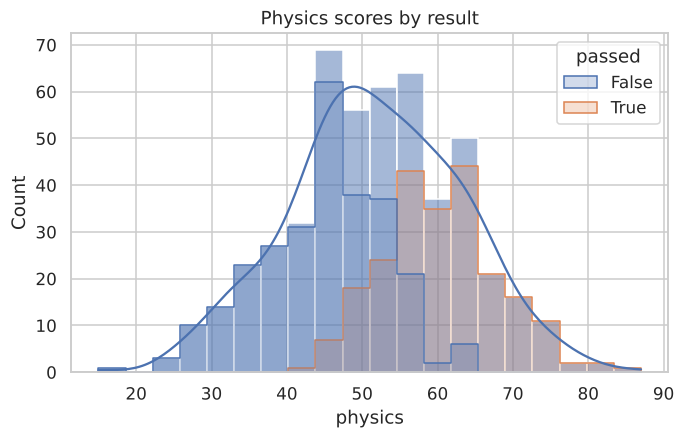

In [2]:
sns.histplot(data=exams, x="physics", kde=True)
plt.title("Physics scores")
plt.show()
sns.histplot(data=exams, x="physics", hue="passed", element="step")
plt.title("Physics scores by result")
plt.show()

### In-Class Exercise 2: Weekdays

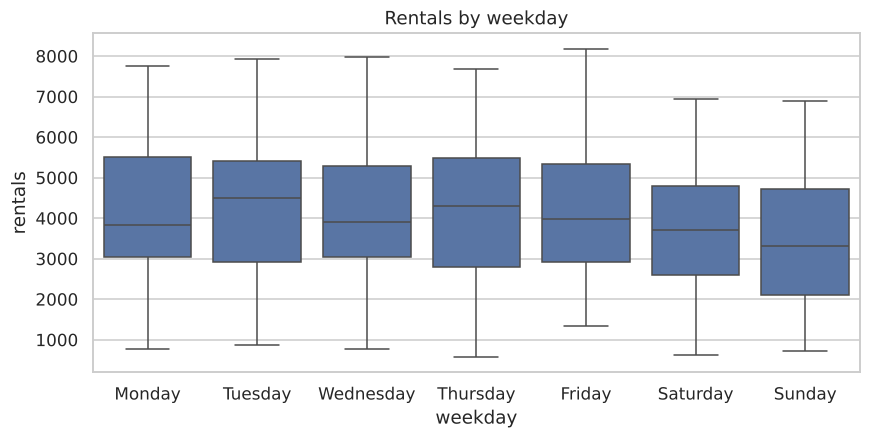

In [3]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
plt.figure(figsize=(9, 4))
sns.boxplot(data=bikes, x="weekday", y="rentals", order=days)
plt.title("Rentals by weekday")
plt.show()

### In-Class Exercise 3: Sleep and Scores

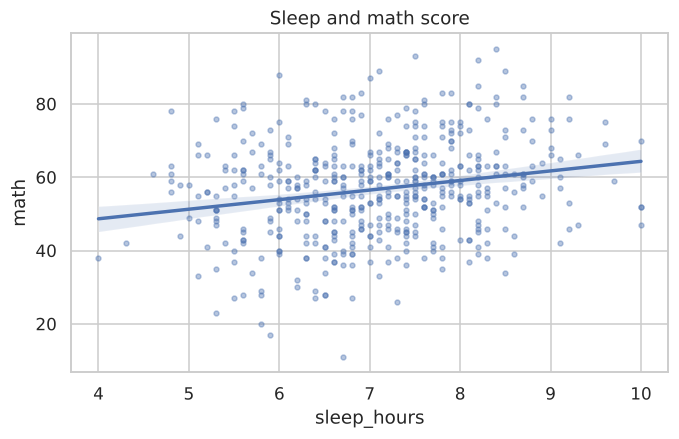

In [4]:
sns.regplot(data=exams, x="sleep_hours", y="math", scatter_kws={"s": 10, "alpha": 0.4})
plt.title("Sleep and math score")
plt.show()

### In-Class Exercise 4: Weather Heatmap

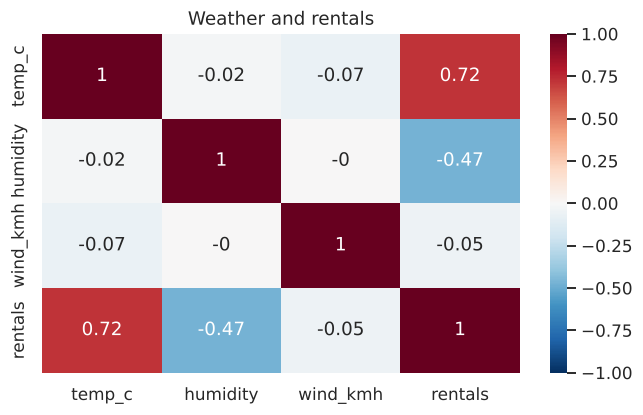

In [5]:
corr = bikes[["temp_c", "humidity", "wind_kmh", "rentals"]].corr().round(2)
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Weather and rentals")
plt.show()

## Part A: Basic

### Exercise 1: Salaries by Department

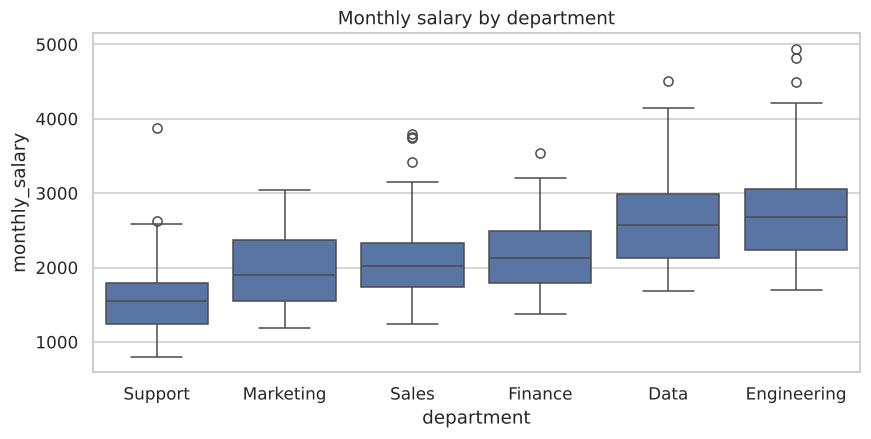

In [6]:
emp = pd.read_csv(DATA_URL + "employees.csv")
order = emp.groupby("department")["monthly_salary"].median().sort_values().index
plt.figure(figsize=(9, 4))
sns.boxplot(data=emp, x="department", y="monthly_salary", order=order)
plt.title("Monthly salary by department")
plt.show()

### Exercise 2: Cafe Payment Methods

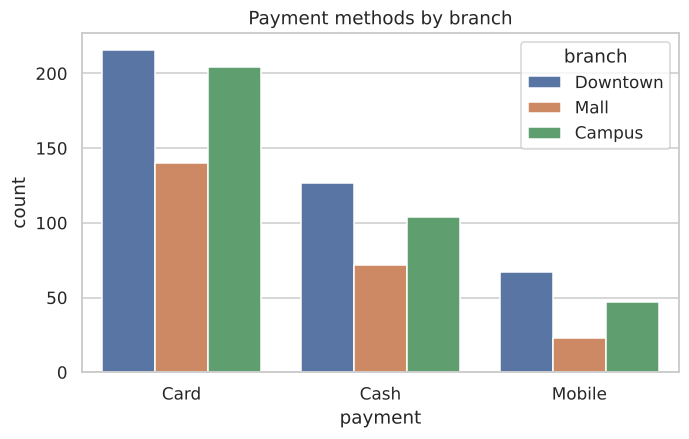

In [7]:
cafe = pd.read_csv(DATA_URL + "cafe_sales.csv")
sns.countplot(data=cafe, x="payment", hue="branch")
plt.title("Payment methods by branch")
plt.show()

## Part B: Intermediate

### Exercise 3: Experience and Salary

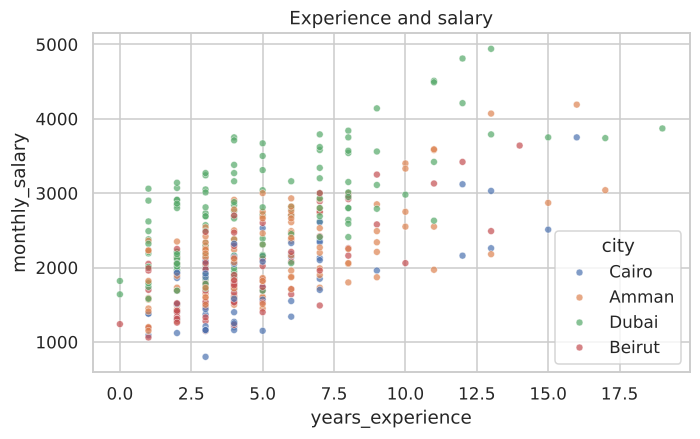

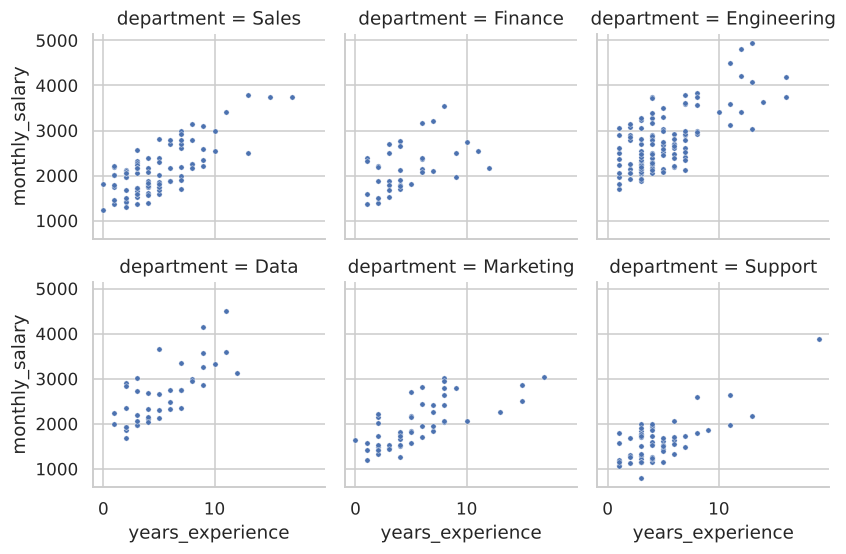

In [8]:
emp = pd.read_csv(DATA_URL + "employees.csv")
sns.scatterplot(data=emp, x="years_experience", y="monthly_salary", hue="city", s=20, alpha=0.7)
plt.title("Experience and salary")
plt.show()
sns.relplot(data=emp, x="years_experience", y="monthly_salary", col="department", col_wrap=3, s=12, height=2.6)
plt.show()
# Salary rises with experience in every department; Engineering and Data rise fastest, and Dubai pays more at every level.

### Exercise 4: Exam Results by Class

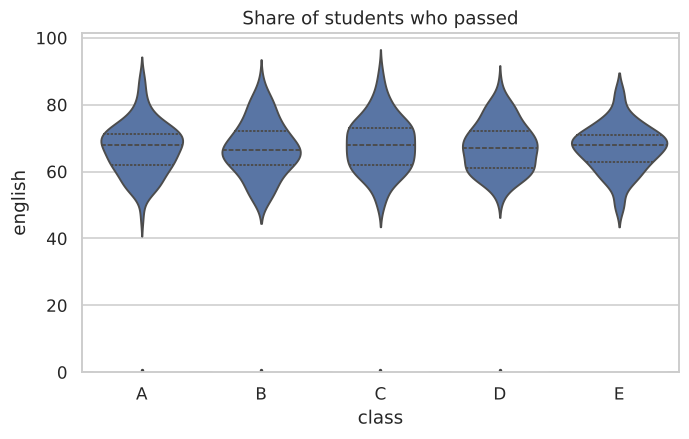

In [9]:
sns.violinplot(data=exams, x="class", y="english", order=list("ABCDE"), inner="quartile")
plt.title("English scores by class")
plt.show()
sns.barplot(data=exams, x="class", y="passed", order=list("ABCDE"))
plt.title("Share of students who passed")
plt.show()

## Part C: Challenge

### Exercise 5: A Pair Plot

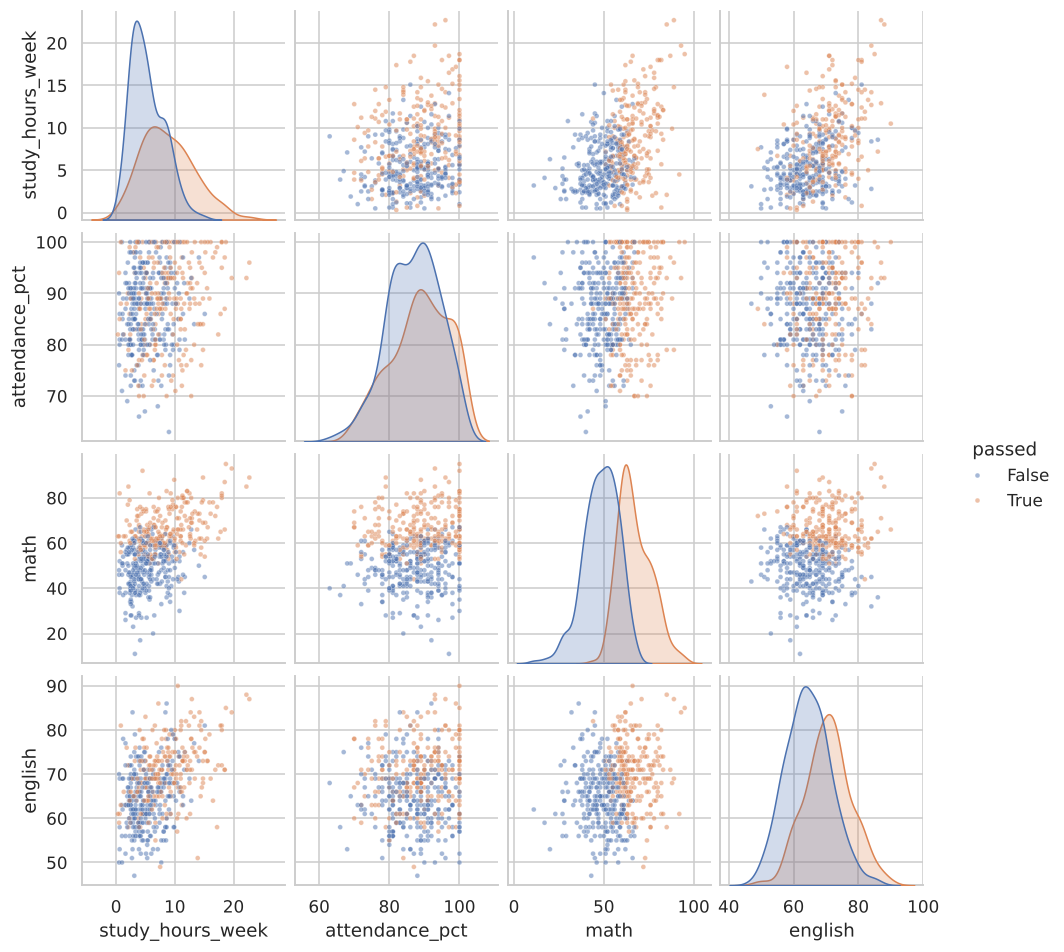

In [10]:
sns.pairplot(exams[["study_hours_week", "attendance_pct", "math", "english", "passed"]],
             hue="passed", plot_kws={"s": 10, "alpha": 0.5}, height=2.2)
plt.show()
# The math score separates the two groups most clearly, especially combined with study hours.

## Part D: Cumulative Project: City Bikes

### Exercise 6: City Bikes Chart Set

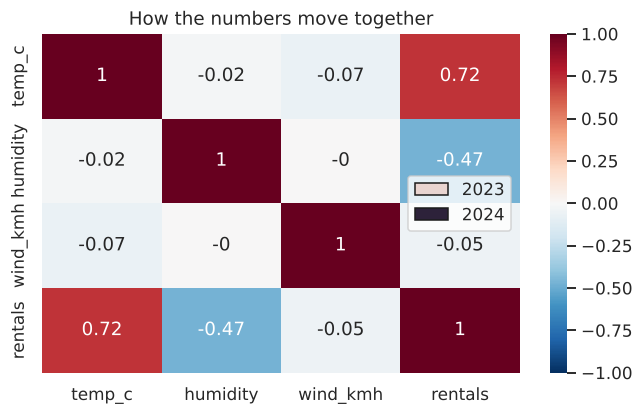

In [11]:
bikes["year"] = bikes["date"].dt.year
order = ["Winter", "Spring", "Summer", "Autumn"]
sns.boxplot(data=bikes, x="season", y="rentals", hue="year", order=order)
plt.title("Rentals per season and year")
plt.show()
# Every season was busier in 2024 than in 2023.

sns.violinplot(data=bikes, x="working_day", y="rentals")
plt.title("Working days and other days")
plt.show()
# Working days have slightly more rentals, but the difference is small.

sns.regplot(data=bikes[bikes["weather"] == "Clear"], x="temp_c", y="rentals", scatter_kws={"s": 8, "alpha": 0.4})
plt.title("Temperature and rentals on clear days")
plt.show()
# On clear days, each extra degree brings more riders.

sns.heatmap(bikes[["temp_c", "humidity", "wind_kmh", "rentals"]].corr().round(2), annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("How the numbers move together")
plt.show()
# Temperature is the weather measure most linked to rentals; humidity works against them.

## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | `hue` maps a category to colours. |
| 2 | B | The line inside the box is the median. |
| 3 | B | Figure-level functions such as `relplot` accept `col=` and `row=`. |
| 4 | B | `barplot` averages the y values of each category. |
| 5 | C | Values near -1 mean that one column goes up when the other goes down. |